# GridRoom engine validation

We check our TypeScript power-flow engine against **pandapower**, an open-source power-system tool used by engineers.

Same 25-house street, same wire impedances, same loads and solar, three cases, smart inverters off
(pandapower doesn't have our volt/VAR loop built in):

1. Sunny spring noon, every house has solar (voltage rises)
2. Heat wave afternoon, no solar (voltage sags)
3. Evening rush with 8 EVs charging (voltage sags)

Our engine's results come from `engine_cases.json`, made by `npx tsx scripts/exportEngineCases.ts`.

In [1]:
import json
import pandapower as pp
import matplotlib.pyplot as plt

with open('engine_cases.json') as f:
    ours = json.load(f)

LOAD_KVAR = {'spring': 0.25, 'heatwave': 1.4, 'evening': 0.6}  # same as realEngine.ts

## Per-unit → ohms

Our engine works in per-unit on a 100 kVA base. pandapower wants ohms, so we pick a voltage base
(0.4 kV) and convert: Z_base = V² / S = 0.4² / 0.1 = 1.6 Ω.
Our wire is 0.004 + j0.004 pu per 40 m, so 0.004 / 0.04 km × 1.6 Ω = **0.16 Ω/km** for both r and x.
The choice of 0.4 kV doesn't matter: per-unit results come out the same for any base.

In [2]:
V_KV, S_MVA = 0.4, 0.1
Z_BASE = V_KV**2 / S_MVA
R_PER_KM = 0.004 / 0.040 * Z_BASE
X_PER_KM = 0.004 / 0.040 * Z_BASE

def pandapower_voltages(case):
    inp = case['input']
    n = inp['numHomes']
    net = pp.create_empty_network(sn_mva=S_MVA)
    source = pp.create_bus(net, vn_kv=V_KV)
    pp.create_ext_grid(net, source, vm_pu=1.02)
    prev = source
    houses = []
    for i in range(n):
        b = pp.create_bus(net, vn_kv=V_KV)
        pp.create_line_from_parameters(net, prev, b, length_km=inp['segmentLengthM'] / 1000,
                                       r_ohm_per_km=R_PER_KM, x_ohm_per_km=X_PER_KM,
                                       c_nf_per_km=0, max_i_ka=1)
        pp.create_load(net, b, p_mw=case['loadKw'][i] / 1000, q_mvar=LOAD_KVAR[inp['scenario']] / 1000)
        if case['solarKw'][i] > 0:
            pp.create_sgen(net, b, p_mw=case['solarKw'][i] / 1000, q_mvar=0)
        houses.append(b)
        prev = b
    pp.runpp(net, tolerance_mva=1e-10)
    return [float(net.res_bus.vm_pu.at[b]) for b in houses]

results = {}
for name, case in ours.items():
    pp_v = pandapower_voltages(case)
    diff = max(abs(a - b) for a, b in zip(case['voltages'], pp_v))
    results[name] = (case['voltages'], pp_v, diff)
    print(f'{name:20s} largest difference = {diff:.2e} pu')

worst = max(r[2] for r in results.values())
print(f'\nLargest difference across all cases: {worst:.2e} pu (goal: under 0.002)')

numba cannot be imported and numba functions are disabled.
Probably the execution is slow.
Please install numba to gain a massive speedup.
(or if you prefer slow execution, set the flag numba=False to avoid this warning!)


spring_all_solar     largest difference = 6.02e-11 pu


numba cannot be imported and numba functions are disabled.
Probably the execution is slow.
Please install numba to gain a massive speedup.
(or if you prefer slow execution, set the flag numba=False to avoid this warning!)


heatwave_no_solar    largest difference = 1.19e-11 pu


numba cannot be imported and numba functions are disabled.
Probably the execution is slow.
Please install numba to gain a massive speedup.
(or if you prefer slow execution, set the flag numba=False to avoid this warning!)


evening_with_evs     largest difference = 4.28e-11 pu

Largest difference across all cases: 6.02e-11 pu (goal: under 0.002)


## Chart for the video and the How We Built It page

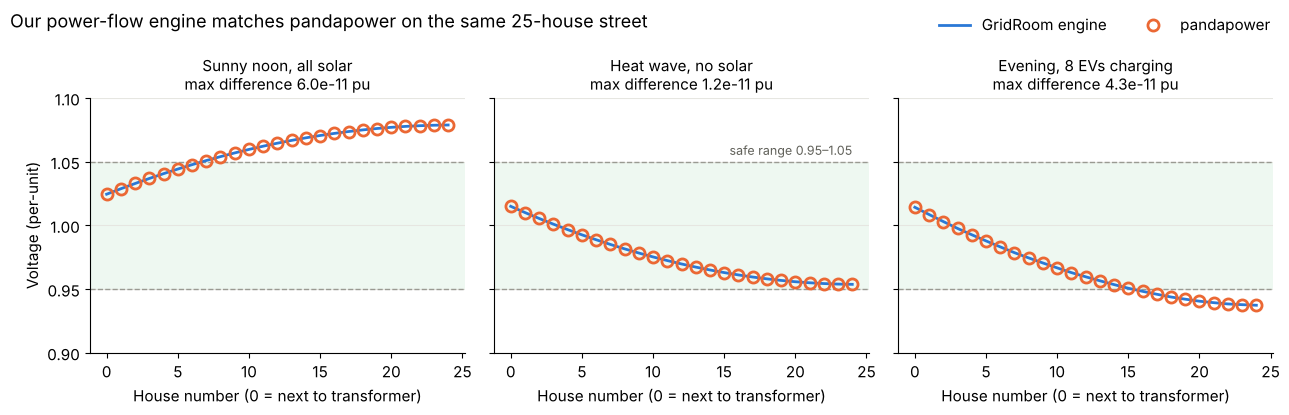

In [3]:
OURS, PP = '#2a78d6', '#eb6834'
TITLES = {'spring_all_solar': 'Sunny noon, all solar',
          'heatwave_no_solar': 'Heat wave, no solar',
          'evening_with_evs': 'Evening, 8 EVs charging'}
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (name, (v_ours, v_pp, diff)) in zip(axes, results.items()):
    x = range(len(v_ours))
    ax.axhspan(0.95, 1.05, color='#2fa84f', alpha=0.08, lw=0)
    for lim in (0.95, 1.05):
        ax.axhline(lim, color='#9a9a92', lw=1, ls='--')
    ax.plot(x, v_ours, color=OURS, lw=2, label='GridRoom engine')
    ax.plot(x, v_pp, 'o', ms=8, mfc='none', mec=PP, mew=2, label='pandapower')
    ax.set_title(f'{TITLES[name]}\nmax difference {diff:.1e} pu', fontsize=11)
    ax.set_xlabel('House number (0 = next to transformer)')
    ax.grid(axis='y', color='#e6e6e1', lw=0.8)
    ax.set_ylim(0.90, 1.10)
axes[0].set_ylabel('Voltage (per-unit)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', ncol=2, frameon=False, bbox_to_anchor=(0.99, 1.0))
axes[1].text(24, 1.053, 'safe range 0.95–1.05', ha='right', va='bottom', color='#5f5f58', fontsize=9)
fig.suptitle('Our power-flow engine matches pandapower on the same 25-house street', fontsize=13, x=0.01, ha='left')
fig.tight_layout()
fig.savefig('validation_chart.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()